# **Studi Kasus: Penerapan Machine Learning untuk Prediksi Prioritas Pemeliharaan Aset Jalan Menggunakan Google Colab**

Sebuah instansi pemerintah daerah memiliki data kondisi sejumlah ruas jalan yang mencakup tingkat kerusakan, volume lalu lintas, panjang jalan, dan biaya perbaikan. Instansi tersebut ingin memanfaatkan teknologi Machine Learning (ML) untuk membantu memprediksi kategori prioritas pemeliharaan jalan berdasarkan pola data yang tersedia. Permasalahan yang dihadapi adalah proses penentuan prioritas masih dilakukan secara manual sehingga membutuhkan waktu dan berpotensi menghasilkan keputusan yang kurang konsisten. Untuk mengatasi masalah tersebut, mahasiswa diminta membangun model ML menggunakan Python melalui Google Colab. Model akan dilatih menggunakan data berlabel yang berisi karakteristik jalan dan kategori prioritasnya, kemudian dievaluasi untuk mengetahui kemampuannya dalam memprediksi kategori pada data yang belum pernah dilihat sebelumnya.

Dalam studi kasus ini, mahasiswa menerapkan pendekatan Supervised Learning dengan metode klasifikasi menggunakan algoritma Decision Tree. Alur pengerjaan meliputi pembuatan dataset simulasi, pemeriksaan dan preprocessing data, pemilihan fitur, pembagian data menjadi data training dan testing, pelatihan model, serta evaluasi kinerja menggunakan akurasi dan classification report. Hasil prediksi kemudian dapat digunakan untuk memahami bagaimana ML mengenali pola dari data historis dan membantu proses pengambilan keputusan. Namun, karena dataset yang digunakan bersifat sintetis dan relatif kecil, hasilnya hanya ditujukan untuk pembelajaran, bukan untuk menentukan pemeliharaan jalan yang sebenarnya.

=== DATASET ===


,kerusakan,lalu_lintas,panjang_km,skor,prioritas
0,5,5,1.2,5.0,Sangat Tinggi
1,4,4,0.8,4.0,Tinggi
2,3,5,1.5,3.6,Tinggi
3,5,3,2.0,4.4,Tinggi
4,2,2,0.7,2.0,Rendah
5,4,5,1.0,4.3,Tinggi
6,5,4,1.8,4.7,Sangat Tinggi
7,1,2,0.5,1.3,Rendah
8,3,3,1.1,3.0,Sedang
9,4,5,1.4,4.3,Tinggi



Distribusi kategori:
prioritas
Rendah           14
Tinggi           11
Sangat Tinggi     8
Sedang            7
Name: count, dtype: int64

Jumlah data training: 30
Jumlah data testing: 10

=== EVALUASI MODEL ===
Akurasi: 0.8

Classification Report:
               precision    recall  f1-score   support

       Rendah       0.75      1.00      0.86         3
       Sedang       1.00      1.00      1.00         2
       Tinggi       1.00      0.33      0.50         3
Sangat Tinggi       0.67      1.00      0.80         2

     accuracy                           0.80        10
    macro avg       0.85      0.83      0.79        10
 weighted avg       0.86      0.80      0.77        10



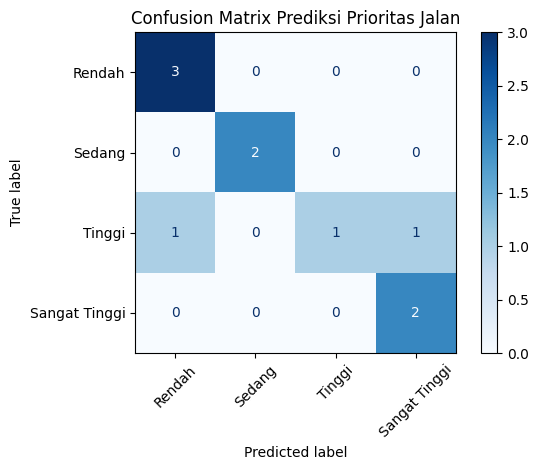

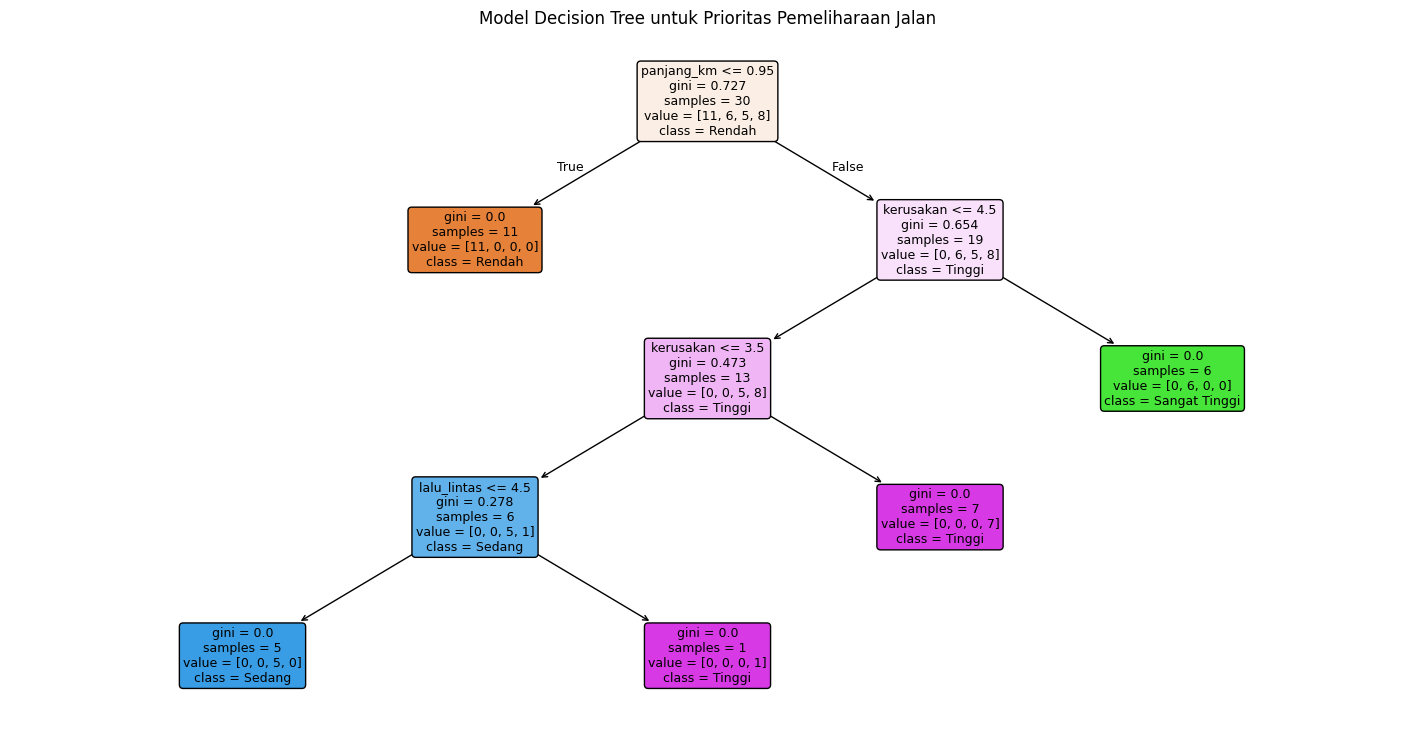


=== PREDIKSI JALAN BARU ===


,kerusakan,lalu_lintas,panjang_km,prediksi_prioritas
0,5,5,1.5,Sangat Tinggi
1,3,3,1.2,Sedang
2,1,2,0.8,Rendah



Catatan: Data dan label bersifat sintetis. Akurasi mengukur kesesuaian dengan label simulasi, bukan kondisi jalan nyata.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

# 1. Membuat dataset sintetis
data = {
    "kerusakan": [
        5, 4, 3, 5, 2, 4, 5, 1, 3, 4,
        2, 1, 5, 3, 4, 2, 5, 1, 3, 4,
        5, 2, 3, 1, 4, 5, 2, 3, 4, 1,
        5, 4, 2, 3, 1, 5, 4, 2, 3, 1
    ],
    "lalu_lintas": [
        5, 4, 5, 3, 2, 5, 4, 2, 3, 5,
        3, 1, 5, 4, 3, 2, 5, 1, 4, 3,
        4, 2, 3, 1, 5, 5, 3, 2, 4, 1,
        5, 4, 2, 3, 1, 4, 5, 3, 2, 1
    ],
    "panjang_km": [
        1.2, 0.8, 1.5, 2.0, 0.7, 1.0, 1.8, 0.5, 1.1, 1.4,
        0.9, 0.6, 1.7, 1.3, 1.0, 0.8, 2.1, 0.4, 1.2, 1.5,
        1.6, 0.7, 1.1, 0.5, 1.8, 2.0, 0.9, 1.4, 1.3, 0.6,
        1.9, 1.1, 0.8, 1.5, 0.7, 1.6, 1.4, 0.9, 1.2, 0.5
    ]
}

df = pd.DataFrame(data)

# 2. Membuat label target berdasarkan aturan simulasi

df["skor"] = (
    0.7 * df["kerusakan"]
    + 0.3 * df["lalu_lintas"]
)

def kategori_prioritas(skor):
    if skor >= 4.5:
        return "Sangat Tinggi"
    elif skor >= 3.5:
        return "Tinggi"
    elif skor >= 2.5:
        return "Sedang"
    else:
        return "Rendah"

df["prioritas"] = df["skor"].apply(kategori_prioritas)

print("=== DATASET ===")
display(df.head(10))

print("\nDistribusi kategori:")
print(df["prioritas"].value_counts())

# 3. Preprocessing dan pemilihan fitur
fitur = ["kerusakan", "lalu_lintas", "panjang_km"]
X = df[fitur]
y = df["prioritas"]

# 4. Membagi data training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("\nJumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

# 5. Melatih model Decision Tree
model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

model.fit(X_train, y_train)

# 6. Melakukan prediksi pada data testing
y_pred = model.predict(X_test)

print("\n=== EVALUASI MODEL ===")
print("Akurasi:", round(accuracy_score(y_test, y_pred), 3))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=["Rendah", "Sedang", "Tinggi", "Sangat Tinggi"],
        zero_division=0
    )
)

# 7. Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["Rendah", "Sedang", "Tinggi", "Sangat Tinggi"],
    xticks_rotation=45,
    cmap="Blues"
)
plt.title("Confusion Matrix Prediksi Prioritas Jalan")
plt.tight_layout()
plt.show()

# 8. Visualisasi pohon keputusan
plt.figure(figsize=(18, 9))
plot_tree(
    model,
    feature_names=fitur,
    class_names=model.classes_,
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("Model Decision Tree untuk Prioritas Pemeliharaan Jalan")
plt.show()

# 9. Simulasi prediksi data baru
jalan_baru = pd.DataFrame({
    "kerusakan": [5, 3, 1],
    "lalu_lintas": [5, 3, 2],
    "panjang_km": [1.5, 1.2, 0.8]
})

prediksi = model.predict(jalan_baru)

jalan_baru["prediksi_prioritas"] = prediksi

print("\n=== PREDIKSI JALAN BARU ===")
display(jalan_baru)

print(
    "\nCatatan: Data dan label bersifat sintetis. "
    "Akurasi mengukur kesesuaian dengan label simulasi, "
    "bukan kondisi jalan nyata."
)


# **Kesimpulan**
Berdasarkan studi kasus penerapan Machine Learning untuk prediksi prioritas pemeliharaan aset jalan menggunakan Google Colab, dapat disimpulkan bahwa ML memungkinkan komputer mempelajari pola dari data untuk menghasilkan prediksi berdasarkan karakteristik yang tersedia. Melalui algoritma Decision Tree, mahasiswa dapat memahami tahapan utama workflow ML, mulai dari pengumpulan dan preprocessing data, pemilihan fitur, pembagian data training dan testing, pelatihan model, hingga evaluasi kinerja. Hasil evaluasi membantu mengidentifikasi kemampuan dan keterbatasan model dalam mengklasifikasikan prioritas pemeliharaan jalan.

Studi kasus ini menunjukkan bahwa penerapan ML dapat membantu proses analisis dan pengambilan keputusan, termasuk dalam bidang pengelolaan aset dan infrastruktur. Namun, keberhasilan model sangat bergantung pada kualitas, jumlah, dan keterwakilan data yang digunakan. Karena dataset pada latihan ini bersifat sintetis, model belum dapat dijadikan dasar keputusan operasional tanpa pengujian menggunakan data nyata yang telah divalidasi. Dengan demikian, mahasiswa tidak hanya belajar membangun model prediksi, tetapi juga memahami pentingnya evaluasi, interpretasi hasil, dan penggunaan teknologi secara bertanggung jawab untuk menyelesaikan permasalahan di dunia nyata.